# Продуктовый кейс Т-Банка (тестовое задание)

## Отчет по результатам A/B-теста

Задание: проводится A/B-тестирование новой формы оплаты ЖКХ с автозаполнением реквизитов. Проверяю, нужно ли запустить ее на всех пользователей. 

- **Воронка оплаты ЖКХ:** 1. Открыл форму -> 2. Ввел реквизиты -> 3. Подтвердил  -> 4. Успешная оплата
- **Ключевая метрика:** Конверсия из шага 1 (открыл форму) в шаг 4 (успешная оплата)
- **Длительность эксперимента:** 1-30 апреля 2024
- **Гипотеза:** Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ

In [1]:
pip install pandas openpyxl

Note: you may need to restart the kernel to use updated packages.


In [4]:
import warnings
warnings.filterwarnings("ignore")

In [7]:
conda env list

# conda environments:
#
base                  *  /Users/evgeniyakhozhay/opt/anaconda3
mirec                    /Users/evgeniyakhozhay/opt/anaconda3/envs/mirec


Note: you may need to restart the kernel to use updated packages.


In [8]:
conda update openpyxl numexpr bottleneck

Solving environment: / 
The environment is inconsistent, please check the package plan carefully
The following packages are causing the inconsistency:

  - defaults/noarch::dask-core==2021.10.0=pyhd3eb1b0_0
  - defaults/noarch::babel==2.9.1=pyhd3eb1b0_0
  - defaults/noarch::tifffile==2021.7.2=pyhd3eb1b0_2
  - defaults/osx-64::daal4py==2021.3.0=py39h01d92e1_0
  - defaults/noarch::jupyterlab_server==2.8.2=pyhd3eb1b0_0
  - defaults/osx-64::scipy==1.7.1=py39h88652d9_2
  - defaults/noarch::cookiecutter==1.7.2=pyhd3eb1b0_0
  - defaults/noarch::imageio==2.9.0=pyhd3eb1b0_0
  - defaults/osx-64::numba==0.54.1=py39hae1ba45_0
  - defaults/osx-64::jupyter==1.0.0=py39hecd8cb5_7
  - defaults/osx-64::bottleneck==1.3.2=py39he3068b8_1
  - defaults/osx-64::mkl_random==1.2.2=py39hb2f4e1b_0
  - defaults/noarch::conda-repo-cli==1.0.4=pyhd3eb1b0_0
  - defaults/osx-64::patsy==0.5.2=py39hecd8cb5_0
  - defaults/osx-64::nbconvert==6.1.0=py39hecd8cb5_0
  - defaults/osx-64::imagecodecs==2021.8.26=py39ha952a84_0
  

In [78]:
pip install "openpyxl>=3.1.0"

Note: you may need to restart the kernel to use updated packages.


In [79]:
import pandas as pd

Анализ проведен на основе данных из файла case_gkh_ab.xlsx, содержащего два листа. Лист «Пользователи» включает информацию обо всех клиентах и их принадлежности к контрольной или тестовой группе. Лист «Платежи» содержит данные о транзакциях ЖКХ и временные метки прохождения каждого этапа воронки оплаты.

In [80]:
tables = pd.read_excel("Desktop/case_gkh_ab.xlsx", sheet_name=None)

In [81]:
df1, df2 = tables.values()

In [82]:
df1

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios
...,...,...,...,...,...
1499,2500,B,39,Москва,ios
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


In [83]:
df2

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
...,...,...,...,...,...,...,...
2656,7657,2500.0,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00
2658,99001,1005.0,A,2024-04-05 10:30:00,2024-04-05 10:33:00,2024-04-05 10:38:00,2024-04-05 10:39:00
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


## Работа с некорректными записями

In [84]:
df1.user_id.nunique()

1504

In [85]:
df2.user_id.nunique()

1501

Всего 1504 пользователя. Есть информация о платежах по 1501 пользователе (почти обо всех). Для эксперимента нужны те пользователи, которые делали оплату в эти дни. По этой причине объединяю таблицы через inner join (будут все пользователи из таблицы с платежами и информация о них).

In [86]:
df = df1.merge(df2, how='inner', on='user_id')

In [87]:
df

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success
0,1001,A,31,Москва,ios,5001,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,1002,A,31,Москва,ios,5002,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,1003,A,25,Москва,android,5003,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,1004,A,20,Москва,ios,5004,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,1004,A,20,Москва,ios,5005,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00
...,...,...,...,...,...,...,...,...,...,...,...
2655,2499,B,42,Москва,ios,7654,B,2024-04-03 10:43:00,2024-04-03 10:47:00,2024-04-03 10:50:00,2024-04-03 10:55:00
2656,2499,B,42,Москва,ios,7655,B,2024-04-14 19:30:00,2024-04-14 19:31:00,2024-04-14 19:38:00,2024-04-14 19:44:00
2657,2499,B,42,Москва,ios,7656,B,2024-04-24 20:54:00,2024-04-24 21:00:00,2024-04-24 21:03:00,2024-04-24 21:08:00
2658,2500,B,39,Москва,ios,7657,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT


### Пропущенные значения

In [88]:
df.isna().sum()

user_id               0
group_x               0
age                   0
city                  1
device_type           0
payment_id            0
group_y               0
step1_opened          0
step2_entered       404
step3_confirmed     941
step4_success      1138
dtype: int64

Нет пустых значений по user_id и payment_id. В таблице «Пользователи» по одному
пользователю отсутствует информация о городе проживания. Все пользователи смогли открыть форму
оплаты: по столбцу нет пустых значений. Есть пропуски по шагам со 2 по 4: на шаге ввода реквизитов
(step2_entered) зафиксировано 404 пропуска, на шаге подтверждения (step3_confirmed) – 941, на шаге
успешной оплаты (step4_success) – 1138.

### Дублированные записи

In [89]:
# отсутствуют дубликаты в id пользователей (из таблицы пользователи)
df1.duplicated(subset=['user_id'], keep=False).sum()

0

In [90]:
# отсутствуют продублированные записи по пользователю и его платежу (уникальные сочетания)
# некоторые пользователи сделали несколько платежей

df2.duplicated(subset=['user_id', 'payment_id'], keep=False).sum()

0

### Ошибки системы сплитования

In [91]:
df.query('group_x != group_y')

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success
16,1010,A,26,Москва,android,99002,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


Ошибка сплитования: есть один пользователь, который в разных таблицах записан в разные группы для A/B-тестирования: пользователь с id 1010. 

In [92]:
df.query("user_id == 1010")

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success
15,1010,A,26,Москва,android,5015,A,2024-04-27 13:26:00,NaT,NaT,NaT
16,1010,A,26,Москва,android,99002,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


По одному из двух его платежей(payment_id = 99002) в таблице «Платежи» он записан в группу B, но в таблице «Пользователи» пользователь записан в группу A.
Сплитование проводится по пользователям (user_id), а не по платежам (payment_id) и одному пользователю соответствует одна группа. Я не удаляла строку, а "исправила" группу (использовала столбец group_x со значениями группы из таблицы "Пользователи").

Есть смысл проверить, что по другим пользователям, кто за период эксперимента сделал больше одного платежа по ЖКХ, нет ошибки в записи группы (и каждому пользователю соответствует одна группа).

Первоначально выделю пользователей с несколькими платежами за месяц эксперимента.

In [93]:
several_payments = df.groupby('user_id', as_index=False)\
    .payment_id.nunique()\
    .query('payment_id > 1')

several_payments

# 761 пользователь сделал больше одного платежа

,user_id,payment_id
3,1004,3
4,1005,2
6,1007,3
8,1009,2
9,1010,2
...,...,...
1490,2491,2
1491,2492,2
1493,2494,3
1494,2495,2


Для этих пользователей проверяю на ошибки в записи группы.

In [94]:
df[df['user_id'].isin(several_payments['user_id'])]\
    .groupby('user_id').agg({'group_x': 'nunique', 'group_y': 'nunique'})\
    .query('group_x > 1|group_y > 1')

# ошибка уже была выявлена, других нет

,group_x,group_y
user_id,,
1010,1,2


Было выявлено несоответствие только для одного пользователя (тот же с user_id = 1010). У других пользователей группы записаны верно для каждой транзакции.

### Проверка дат платежей, использованных при проведении эксперимента

In [95]:
df.agg({'step1_opened':['min', 'max'],
       'step2_entered':['min', 'max'],
       'step3_confirmed':['min', 'max'],
       'step4_success':['min', 'max']})

,step1_opened,step2_entered,step3_confirmed,step4_success
min,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
max,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


На всех этапах воронки дата попытки находится в диапазоне 1–30 апреля 2024, в период
проведения эксперимента. Лишние платежи не были использованы.

### Проверка на наличие «сломанных» последовательностей воронки

In [96]:
df.query("step1_opened > step2_entered or step2_entered > step3_confirmed or step3_confirmed > step4_success")

# порядок соблюден

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success


In [97]:
df.query("step1_opened > step4_success")

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success


**Вывод:** нет строк, где нарушен порядок (по дате и времени более поздние шаги идут раньше). Порядок соблюдается.

In [98]:
df.query('(step2_entered.isna() & step4_success.notna())')

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success


In [99]:
df.query('(step3_confirmed.isna() & step4_success.notna())')

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success


**Вывод:** Нет таких строк, где есть успешный шаг 2-4, когда предыдущие не заполнены. Корректировки не требовалось.

## Разведочный анализ данных

In [100]:
df.groupby('city', as_index=False).payment_id.nunique()

,city,payment_id
0,Москва,1070
1,Регион,889
2,СПб,700


Соблюдается примерно равномерное распределение платежей по городам, хотя наибольшее их количество приходило из Москвы за период эксперимента. Из СПб – 700 платежей, из другого региона – 889.

In [101]:
df.groupby('device_type', as_index=False).payment_id.nunique()

# равномерно распределены

,device_type,payment_id
0,android,1381
1,ios,1279


1381 платежей было сделано с устройств с операционной системой Android, 1279 – с устройств с операционной системой iOS.

In [102]:
df.groupby('age', as_index=False).payment_id.nunique()\
    .sort_values('payment_id', ascending=False)

,age,payment_id
0,20,171
13,33,134
10,30,131
15,35,126
12,32,124
14,34,122
8,28,119
11,31,116
16,36,110
18,38,107


Наименьшее количество платежей от людей после 50. Наибольшее их количество от пользователей - 28-38 лет.

## Метрики по группам

In [103]:
df.groupby('group_x', as_index=False).user_id.nunique()

# система равномерно распределила пользователей

,group_x,user_id
0,A,751
1,B,750


In [104]:
df.groupby('group_x', as_index=False).payment_id.nunique()

,group_x,payment_id
0,A,1309
1,B,1351


В контрольную группу (A) определили 751 пользователя, в тестовую (B) – 750. В группе A 1309 запущенных платежей, в группе В – 1351.

### Составление воронки

Так как тестируется новая форма оплаты, а пользователи могли совершать несколько платежей, часть которых была успешна завершена, а другая – нет, основная метрика была рассчитана по payment_id. Это позволяет оценить эффективность формы при попытках осуществления разных платежей.

In [105]:
def step_users(df, step_col):
    return df[df[step_col].notna()].groupby('group_x').payment_id.nunique()

In [106]:
funnel = pd.DataFrame({
    'step1_opened': step_users(df, 'step1_opened'),
    'step2_entered': step_users(df, 'step2_entered'),
    'step3_confirmed': step_users(df, 'step3_confirmed'),
    'step4_success': step_users(df, 'step4_success')
})

funnel

,step1_opened,step2_entered,step3_confirmed,step4_success
group_x,,,,
A,1309,1062,759,652
B,1351,1194,960,870


In [107]:
funnel['conversion1_4'] = (funnel['step4_success'] / funnel['step1_opened'] * 100).round(1)

In [108]:
funnel

,step1_opened,step2_entered,step3_confirmed,step4_success,conversion1_4
group_x,,,,,
A,1309,1062,759,652,49.8
B,1351,1194,960,870,64.4


### Воронка в процентах

In [109]:
step_conv = ((funnel / funnel.shift(1, axis=1)) * 100).round(2)\
    .iloc[:, 1:4]

step_conv

,step2_entered,step3_confirmed,step4_success
group_x,,,
A,81.13,71.47,85.90
B,88.38,80.40,90.62


In [110]:
step_conv.columns = [
    '1. Открыл форму -> 2. Ввел реквизиты',
    '2. Ввел реквизиты -> 3. Подтвердил',
    '3. Подтвердил -> 4. Успешная оплата'
]

In [111]:
step_conv.T

group_x,A,B
1. Открыл форму -> 2. Ввел реквизиты,81.13,88.38
2. Ввел реквизиты -> 3. Подтвердил,71.47,80.40
3. Подтвердил -> 4. Успешная оплата,85.90,90.62


(0.0, 105.0)

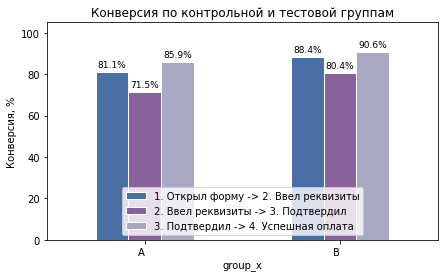

In [112]:
import matplotlib.pyplot as plt


ax = step_conv.plot(kind='bar', figsize=(7, 4), color=['#4A6FA5', '#8A629B', '#A9A9C4'], edgecolor='white')
plt.title('Конверсия по контрольной и тестовой группам')
plt.ylabel('Конверсия, %')
plt.xticks(rotation=0, ha='right')
plt.legend(loc='lower center') 

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)
plt.ylim(0, 105)

**Вывод:** предварительно перед проведением тестирования можно отметить увеличение конверсии на каждом шаге воронки в группе B по сравнению с группой A. На шаге перехода к введению реквизитов конверсия возросла на ~ 7 п.п., на последнем шаге – на почти 5 п.п. Наиболее резкое сокращение в группе А на моменте подтверждения оплаты. В новой форме конверсия на этом шаге стала выше почти на 9%. Вероятно, пользователи могли допускать ошибки при введении реквизитов, что препятствовало подтверждению платежа. При форме с автозаполнением конверсия в 3 шаг возросла.

In [154]:
# длительность каждого перехода в секундах

df['time_1_to_2'] = (df['step2_entered'] - df['step1_opened']).dt.total_seconds()
df['time_2_to_3'] = (df['step3_confirmed'] - df['step2_entered']).dt.total_seconds()
df['time_3_to_4'] = (df['step4_success'] - df['step3_confirmed']).dt.total_seconds()

# медианное время для каждой группы
speed_analysis = df.groupby('group_x')[['time_1_to_2', 'time_2_to_3', 'time_3_to_4']].median()

display(speed_analysis.round(2))

,time_1_to_2,time_2_to_3,time_3_to_4
group_x,,,
A,60.0,240.0,330.0
B,60.0,240.0,360.0


Сравнивая длительность перехода от одного этапа воронки к другому для пользователей разных форм оплаты, произошло увеличение времени, которое занимает переход от подверждения к успешной оплате, для пользователей тестовой группы (но на 30 секунд по медиане). На других этапах медианное время не изменилось. Это может быть обусловлено и тем, что больше пользователей стали походить до последнего шага оплаты, что повысило нагрузку на систему, и стало причиной увеличения времени обработки платежей. 

In [160]:
df_time = df[['group_x', 'payment_id', 'step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']].copy()

In [161]:
df_time = df_time.set_index('step4_success')

In [162]:
load_15min = df_time.groupby('group_x')['payment_id'].resample('15Min').count().reset_index()

In [163]:
load_15min.query('payment_id >= 3')

,group_x,step4_success,payment_id
1230,A,2024-04-13 20:00:00,3
2842,A,2024-04-30 15:00:00,3
2945,B,2024-04-01 17:30:00,3
3013,B,2024-04-02 10:30:00,3
3156,B,2024-04-03 22:15:00,3
3904,B,2024-04-11 17:15:00,3
3983,B,2024-04-12 13:00:00,3
4032,B,2024-04-13 01:15:00,3
4192,B,2024-04-14 17:15:00,4
4194,B,2024-04-14 17:45:00,3


В целом нагрузка на данном этапе была умеренной. не было выявлено критического количества одновременных транзакций. При этом случаи высокой активности в 15-минутный интервал (больше 3 платежей) чаще встречались для пользователей тестовой группы (новой формы). Вероятно, это также связано с ростом количества пользователей, которые дошли до успешной оплаты. 

### Результаты A/B-теста

**Гипотеза**: Новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ.

**Ключевая метрика:** конверсия из шага 1 (открыл форму) в шаг 4 (успешная оплата).

(0.0, 81.0)

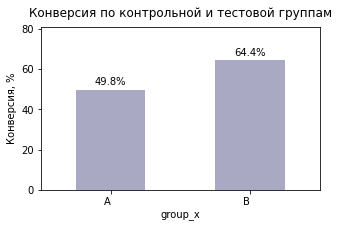

In [116]:
ax = funnel['conversion1_4'].plot(kind='bar', figsize=(5, 3), color='#A9A9C4')
plt.title('Конверсия по контрольной и тестовой группам', pad=10)
plt.ylabel('Конверсия, %')
plt.xticks(rotation=0, ha='right')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)

plt.ylim(0, 81)

Метрика конверсии из открытия формы оплаты в успешную оплату возросла с 49,8% до 64,4%. Наблюдается рост конверсии на 14,6 п.п.

Для проверки на статистическую значимость изменения в конверсии использую критерий Хи-квадрат.

Гипотезы:
- H0: нет взаимосвязи между переменными принадлежности к контрольной или тестовой группе (с разницей в используемой форме оплаты) и фактом успешности оплаты
- Н1: есть взаимосвязь между используемой формой оплаты и фактом ее успешности

In [117]:
from scipy.stats import chi2_contingency

1 способ. Через таблицу с воронкой пользователей получить таблицу сопряженности, где по каждой группе есть количество успешных и неуспешных завершений оплаты.

In [118]:
group_a = funnel.index[0]
group_b = funnel.index[1]

In [119]:
success_pay_A = funnel.loc[group_a, 'step4_success']
fail_pay_A = funnel.loc[group_a, 'step1_opened'] - success_pay_A

success_pay_B = funnel.loc[group_b, 'step4_success']
fail_pay_B = funnel.loc[group_b, 'step1_opened'] - success_pay_B

In [120]:
# таблица сопряженности

contingency = [[success_pay_A, fail_pay_A],
                         [success_pay_B, fail_pay_B]]

In [121]:
contingency

[[652, 657], [870, 481]]

In [122]:
stat, p, dof, expected = chi2_contingency(contingency)

In [123]:
stat, p

(57.20124679629859, 3.9342169177333685e-14)

2 способ. Для проверки построю таблицу сопряженности другим способом - методом crosstab. Дополнительно ввела бинарную переменную по столбцу step4_success - is_success: 1, если оплата успешна (значение не пустое), 0 – если не успешна. 

In [124]:
df_funnel = df[df['step1_opened'].notnull()].copy()
df_funnel

,user_id,group_x,age,city,device_type,payment_id,group_y,step1_opened,step2_entered,step3_confirmed,step4_success,time_1_to_2,time_2_to_3,time_3_to_4,hour_step1,hour_step2,hour_step3,hour_step4
0,1001,A,31,Москва,ios,5001,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,240.0,NaN,NaN,6,6.0,NaN,NaN
1,1002,A,31,Москва,ios,5002,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,180.0,NaN,NaN,7,7.0,NaN,NaN
2,1003,A,25,Москва,android,5003,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,240.0,NaN,NaN,20,20.0,NaN,NaN
3,1004,A,20,Москва,ios,5004,A,2024-04-09 16:02:00,NaT,NaT,NaT,NaN,NaN,NaN,16,NaN,NaN,NaN
4,1004,A,20,Москва,ios,5005,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,480.0,180.0,300.0,3,3.0,3.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2655,2499,B,42,Москва,ios,7654,B,2024-04-03 10:43:00,2024-04-03 10:47:00,2024-04-03 10:50:00,2024-04-03 10:55:00,240.0,180.0,300.0,10,10.0,10.0,10.0
2656,2499,B,42,Москва,ios,7655,B,2024-04-14 19:30:00,2024-04-14 19:31:00,2024-04-14 19:38:00,2024-04-14 19:44:00,60.0,420.0,360.0,19,19.0,19.0,19.0
2657,2499,B,42,Москва,ios,7656,B,2024-04-24 20:54:00,2024-04-24 21:00:00,2024-04-24 21:03:00,2024-04-24 21:08:00,360.0,180.0,300.0,20,21.0,21.0,21.0
2658,2500,B,39,Москва,ios,7657,B,2024-04-11 07:01:00,2024-04-11 07:04:00,NaT,NaT,180.0,NaN,NaN,7,7.0,NaN,NaN


In [125]:
df_funnel['is_success'] = df_funnel['step4_success'].notnull().astype(int)

In [126]:
contingency = pd.crosstab(df_funnel['group_x'],
                          df_funnel['is_success'])

In [127]:
df_cross = contingency.copy()

In [128]:
contingency = contingency.rename(columns = {1: 'Успешная оплата',
                             0: 'Неуспешная оплата'})

contingency.index = ['Контрольная группа (A)', 'Тестовая группа (B)']

In [129]:
contingency.columns.name = None 

In [130]:
contingency['Конверсия 1 -> 4 (в %)'] = funnel['conversion1_4'].values

In [131]:
contingency

,Неуспешная оплата,Успешная оплата,Конверсия 1 -> 4 (в %)
Контрольная группа (A),657,652,49.8
Тестовая группа (B),481,870,64.4


In [132]:
stat, p, dof, expected = chi2_contingency(df_cross)

In [133]:
stat, p

(57.201246796298584, 3.934216917733383e-14)

(array([0, 1]),
 [Text(0, 0, 'Контрольная группа (A)'), Text(1, 0, 'Тестовая группа (B)')])

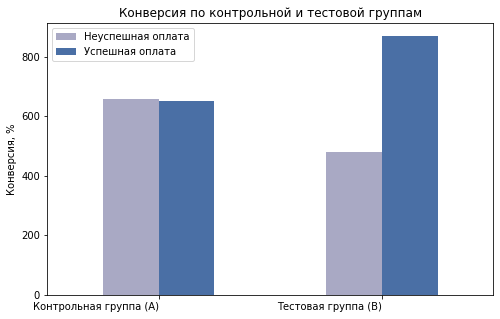

In [165]:
ax = contingency[['Неуспешная оплата', 'Успешная оплата']].plot(
    kind='bar', 
    figsize=(8, 5), 
    color=['#A9A9C4', '#4A6FA5'])

plt.title('Конверсия по контрольной и тестовой группам')
plt.ylabel('Конверсия, %')
plt.xticks(rotation=0, ha='right')

## Вывод

- Результат не изменился, p-value = 3.934216917733383e-14. p-value ниже уровня значимости 0,05. Нулевая гипотеза об отсутствии взаимосвязи отклоняется. Следовательно, есть статистически значимая взаимосвязь между принадлежностью к группам эксперимента (с разницей в форме оплаты) и успешным завершением платежа.
- Подтверждается гипотеза об увеличении доли успешных оплат ЖКХ в результате введения новой формы с автозаполнением реквизитов.

-> **Рекомендуется запустить форму на всех пользователей.**

Дополнительно: Новая форма внесла положительные изменения в пошаговую конверсию. Отдельно стоит отметить увеличение конверсии из введения реквизитов в подтверждение платежа. Это шаг, на котором при использовании старой формы наблюдалась наибольшая потеря в пользователях.